In [1]:
from google.colab import drive
from pathlib import Path
import zipfile
drive.mount('/content/drive')
zip_files = list(Path('/content/drive/MyDrive').rglob('*.zip'))
for i, p in enumerate(zip_files): print(i, p)
choice = int(input('Number of the NUS Dataset II ZIP: '))
zip_path = zip_files[choice]
DATA_ROOT = Path('/content/nus_data')
DATA_ROOT.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(zip_path) as z: z.extractall(DATA_ROOT)
print('Extracted:', zip_path, '->', DATA_ROOT)

Mounted at /content/drive
0 /content/drive/MyDrive/Colab Notebooks/ER.zip
1 /content/drive/MyDrive/Colab Notebooks/archive.zip
2 /content/drive/MyDrive/Colab Notebooks/NUS-Hand-Posture-Dataset-I.zip
3 /content/drive/MyDrive/Colab Notebooks/NUS-Hand-Posture-Dataset-II.zip
Number of the NUS Dataset II ZIP: 3
Extracted: /content/drive/MyDrive/Colab Notebooks/NUS-Hand-Posture-Dataset-II.zip -> /content/nus_data


In [2]:
import re, pandas as pd, numpy as np
from collections import Counter
IMAGE_EXTS={'.jpg','.jpeg','.png'}

def get_label(p):
    parts=[p.stem]+list(reversed(p.parts))
    for part in parts:
        m=re.match(r'^([a-j])(?:_HN)?(?:[_-]?\d+)?$',part,re.I)
        if m: return m.group(1).lower()
        m=re.match(r'^([a-j])(?:_HN)?[_-]',part,re.I)
        if m: return m.group(1).lower()
    return None

rows=[]
for p in DATA_ROOT.rglob('*'):
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS and 'background' not in str(p).lower():
        label=get_label(p)
        if label: rows.append({'path':str(p),'label':label})
df=pd.DataFrame(rows)
print('Labeled images:',len(df))
print(df.label.value_counts().sort_index())
print('Example files:',df.path.head(12).to_list())
assert len(df)>0, 'Could not infer a-j labels from names. Inspect Example files and tell me what they look like.'
assert set(df.label)==set('abcdefghij'), f'Expected a-j classes, found {sorted(df.label.unique())}'

Labeled images: 760
label
a    76
b    76
c    76
d    76
e    76
f    76
g    76
h    76
i    76
j    76
Name: count, dtype: int64
Example files: ['/content/nus_data/NUS Hand Posture dataset-II/Hand Postures/c.jpg', '/content/nus_data/NUS Hand Posture dataset-II/Hand Postures/e.jpg', '/content/nus_data/NUS Hand Posture dataset-II/Hand Postures/a.jpg', '/content/nus_data/NUS Hand Posture dataset-II/Hand Postures/i.jpg', '/content/nus_data/NUS Hand Posture dataset-II/Hand Postures/h.jpg', '/content/nus_data/NUS Hand Posture dataset-II/Hand Postures/d.jpg', '/content/nus_data/NUS Hand Posture dataset-II/Hand Postures/f.jpg', '/content/nus_data/NUS Hand Posture dataset-II/Hand Postures/g.jpg', '/content/nus_data/NUS Hand Posture dataset-II/Hand Postures/b.jpg', '/content/nus_data/NUS Hand Posture dataset-II/Hand Postures/j.jpg', '/content/nus_data/NUS Hand Posture dataset-II/Hand Postures with human noise/i_HN (4).jpg', '/content/nus_data/NUS Hand Posture dataset-II/Hand Postures with hum

In [3]:
from sklearn.model_selection import train_test_split
import tensorflow as tf
from pathlib import Path
tf.keras.utils.set_random_seed(42)
CLASSES=list('abcdefghij')
class_to_id={c:i for i,c in enumerate(CLASSES)}
df['y']=df.label.map(class_to_id).astype('int32')
train_df, temp_df=train_test_split(df,test_size=.30,random_state=42,stratify=df.y)
val_df,test_df=train_test_split(temp_df,test_size=.50,random_state=42,stratify=temp_df.y)
print('Train / val / test:',len(train_df),len(val_df),len(test_df))
SIZE=(128,128); BATCH=32; AUTOTUNE=tf.data.AUTOTUNE
def make_ds(frame,shuffle=False):
    ds=tf.data.Dataset.from_tensor_slices((frame.path.to_numpy(),frame.y.to_numpy(dtype=np.int32)))
    if shuffle: ds=ds.shuffle(len(frame),seed=42)
    def load(path,label):
        im=tf.io.decode_image(tf.io.read_file(path),channels=3,expand_animations=False)
        im=tf.image.resize(im,SIZE)
        return tf.cast(im,tf.float32)/255.,label
    return ds.map(load,num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)
train_ds=make_ds(train_df,True); val_ds=make_ds(val_df); test_ds=make_ds(test_df)

Train / val / test: 532 114 114


In [9]:
from tensorflow import keras
from tensorflow.keras import layers

base = keras.applications.MobileNetV2(
    input_shape=(*SIZE, 3),
    include_top=False,
    weights="imagenet"
)
base.trainable = False

inputs = keras.Input(shape=(*SIZE, 3))
x = layers.Rescaling(2.0, offset=-1)(inputs)  # MobileNetV2 input scaling
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(10, activation="softmax")(x)

model = keras.Model(inputs, outputs)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=5, restore_best_weights=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=callbacks
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 23s 720ms/step - accuracy: 0.1560 - loss: 2.8591 - val_accuracy: 0.1316 - val_loss: 2.3855
Epoch 2/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.2312 - loss: 2.2681 - val_accuracy: 0.2193 - val_loss: 2.1115
Epoch 3/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.3665 - loss: 1.8424 - val_accuracy: 0.2895 - val_loss: 1.9051
Epoch 4/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.4680 - loss: 1.5443 - val_accuracy: 0.3596 - val_loss: 1.7932
Epoch 5/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 0.5564 - loss: 1.3369 - val_accuracy: 0.4386 - val_loss: 1.6506
Epoch 6/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.6165 - loss: 1.1610 - val_accuracy: 0.4649 - val_loss: 1.5707
Epoch 7/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.6598 - loss: 1.0464 - val_accuracy: 0.5175 - val_loss: 1.4875
Epoch 8/20
17/17 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accurac

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.5526 - loss: 1.2944
Image-level test accuracy: 55.263%


              precision    recall  f1-score   support

           a       0.29      0.18      0.22        11
           b       0.75      0.27      0.40        11
           c       0.33      0.64      0.44        11
           d       0.60      0.75      0.67        12
           e       0.64      0.58      0.61        12
           f       0.67      0.67      0.67        12
           g       0.86      0.55      0.67        11
           h       0.36      0.33      0.35        12
           i       0.57      0.73      0.64        11
           j       0.75      0.82      0.78        11

    accuracy                           0.55       114
   macro avg       0.58      0.55      0.54       114
weighted avg       0.58      0.55      0.54       114

Saved to Drive: ps49_nus_webcam.keras


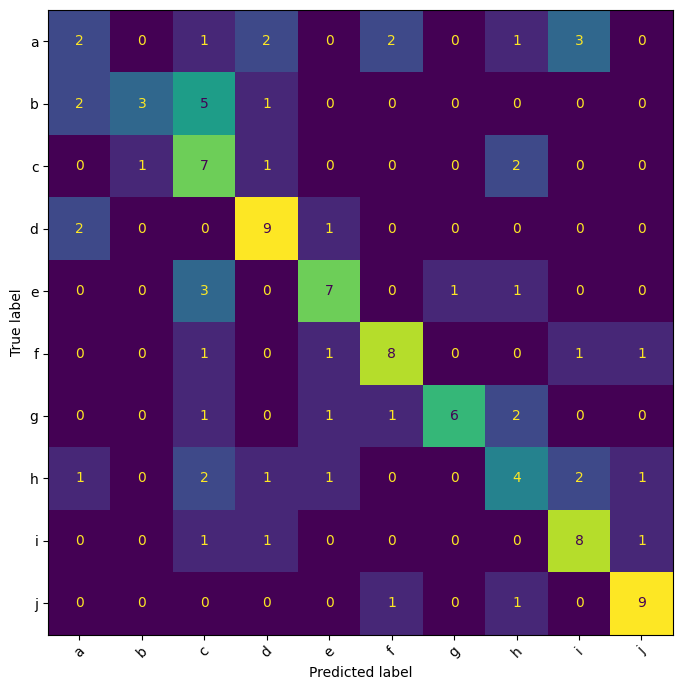

In [10]:
from sklearn.metrics import classification_report,confusion_matrix,ConfusionMatrixDisplay
loss,acc=model.evaluate(test_ds)
print(f'Image-level test accuracy: {acc:.3%}')
y_true=np.concatenate([y.numpy() for _,y in test_ds])
y_pred=model.predict(test_ds,verbose=0).argmax(axis=1)
print(classification_report(y_true,y_pred,labels=np.arange(10),target_names=CLASSES,zero_division=0))
fig,ax=plt.subplots(figsize=(8,7))
ConfusionMatrixDisplay(confusion_matrix(y_true,y_pred,labels=np.arange(10)),display_labels=CLASSES).plot(ax=ax,xticks_rotation=45,colorbar=False)
plt.tight_layout()
model.save('/content/drive/MyDrive/ps49_nus_webcam.keras')
print('Saved to Drive: ps49_nus_webcam.keras')

<IPython.core.display.Javascript object>

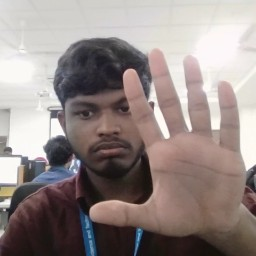

Prediction: b | confidence: 48.5%
Top 3: [('b', 0.48467573523521423), ('a', 0.34714487195014954), ('j', 0.04824809730052948)]


In [11]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
from PIL import Image
import io
display(Javascript("""
async function captureFrame() {
 const box=document.createElement('div'), video=document.createElement('video'), button=document.createElement('button');
 button.textContent='Capture frame'; video.style.width='480px'; box.appendChild(video); box.appendChild(button); document.body.appendChild(box);
 const stream=await navigator.mediaDevices.getUserMedia({video:true}); video.srcObject=stream; await video.play(); await new Promise(resolve=>button.onclick=resolve);
 const canvas=document.createElement('canvas'); canvas.width=256; canvas.height=256; const ctx=canvas.getContext('2d');
 const side=Math.min(video.videoWidth,video.videoHeight), sx=(video.videoWidth-side)/2, sy=(video.videoHeight-side)/2;
 ctx.drawImage(video,sx,sy,side,side,0,0,256,256); const result=canvas.toDataURL('image/jpeg',0.9);
 stream.getTracks().forEach(t=>t.stop()); box.remove(); return result;
}
"""))
data=eval_js('captureFrame()')
frame=Image.open(io.BytesIO(b64decode(data.split(',')[1]))).convert('RGB')
arr=np.asarray(frame.resize(SIZE),dtype=np.float32)[None,...]/255.0
probs=model.predict(arr,verbose=0)[0]
best=int(probs.argmax())
display(frame)
print(f'Prediction: {CLASSES[best]} | confidence: {probs[best]:.1%}')
print('Top 3:',[(CLASSES[i],float(probs[i])) for i in probs.argsort()[-3:][::-1]])

In [12]:
print(f"Final training accuracy: {history.history['accuracy'][-1]:.1%}")
print(f"Best validation accuracy: {max(history.history['val_accuracy']):.1%}")
print("Images per class:")
print(df["label"].value_counts().sort_index())

Final training accuracy: 92.5%
Best validation accuracy: 66.7%
Images per class:
label
a    76
b    76
c    76
d    76
e    76
f    76
g    76
h    76
i    76
j    76
Name: count, dtype: int64
